# EggsPerDay_Model.ipynb
**ICS 3202 — Artificial Intelligence | Project Deliverable 2**

**Project:** An Integrated Enterprise Resource Planning System for Poultry Farm Management

**Goal of this notebook:** build the core of the ERP's ML engine, a model that predicts `EggsPerDay` from a bird's attributes, and evaluate it honestly given that the dataset is partly synthetic.

Steps:
1. Reload the dataset, check its real structure, and clean out impossible records
2. Encode the categorical columns
3. Train and compare regression models
4. Pick and save the final model
5. Limitations: what the scores do and don't show
6. How the ERP uses the model (the `FlockAgent` in `ml_engine/`)

## Setup — load the dataset

In [1]:
# kagglehub can download public Kaggle datasets without an API token, so unlike
# Deliverable 1 there is no kaggle.json upload step. It comes preinstalled in
# Colab; locally, pip install -r requirements.txt first.

import glob
import os

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

folder = kagglehub.dataset_download('phuzoman/egg-producing-chickens')
df = pd.read_csv(glob.glob(os.path.join(folder, '*.csv'))[0])
print(df.shape)
df.head()

(1000, 16)


,GallusID,GallusBreed,Day,Age,GallusWeight,GallusEggColor,GallusEggWeight,AmountOfFeed,EggsPerDay,GallusCombType,SunLightExposure,GallusClass,GallusLegShanksColor,GallusBeakColor,GallusEarLobesColor,GallusPlumage
0,Marans1,Marans,1,883,3000,Brown,41.19,114,1,Single,7,Continental,White,White,NaN,Blue Copper
1,Marans1,Marans,2,883,3000,Brown,41.19,114,1,Single,7,Continental,White,White,NaN,Blue Copper
2,Marans1,Marans,3,883,3000,Brown,41.19,114,1,Single,7,Continental,White,White,NaN,Blue Copper
3,Marans1,Marans,4,883,3000,Brown,41.19,114,1,Single,7,Continental,White,White,NaN,Blue Copper
4,Marans1,Marans,5,883,3000,Brown,41.19,114,1,Single,7,Continental,White,White,NaN,Blue Copper


## 1. What the data actually looks like

Deliverable 1 treated the file as 1,000 separate observations. Before training anything, it is worth checking whether that is really true. Every bird has a `GallusID`, so we can see whether a bird's values change from one day to the next.

In [2]:
# For every column, count how many distinct values it takes within the same
# bird. A column that never takes more than one value per bird is just being
# copied from day to day.
per_bird = df.groupby('GallusID').nunique(dropna=False)
print('Columns that change within a bird:', per_bird.columns[(per_bird > 1).any()].tolist())
print('Distinct birds:', df['GallusID'].nunique())
print()
print(df.groupby('GallusID').size().value_counts().rename('birds with this many rows'))

Columns that change within a bird: ['Day']
Distinct birds: 190

5     180
10     10
Name: birds with this many rows, dtype: int64


Only `Day` changes, so the 1,000 rows are really **190 birds**, each copied 5 (or 10) times with identical values.

This matters for evaluation. If the 1,000 rows were split randomly, copies of the same bird would end up in both the training and the test set, and the model would be marked on birds it has already seen. So the data is collapsed to one row per bird and every split below is made between birds.

In [3]:
# Dropping Day makes each bird's copies identical, so drop_duplicates leaves
# exactly one row per bird.
birds = df.drop(columns='Day').drop_duplicates().reset_index(drop=True)
assert birds['GallusID'].is_unique
print(birds.shape)

(190, 15)


### The target, `EggsPerDay`

In [4]:
print(birds['EggsPerDay'].value_counts())

# Which birds lay nothing, and how old are they compared with the oldest
# bird that still lays?
print()
print(birds.loc[birds['EggsPerDay'] == 0, ['GallusID', 'GallusBreed', 'Age']].sort_values('Age').to_string(index=False))
print()
print('Oldest bird that still lays:', birds.loc[birds['EggsPerDay'] == 1, 'Age'].max(), 'days')

EggsPerDay
1    183
0      7
Name: count, dtype: int64

 GallusID GallusBreed  Age
Marans112      Marans  961
Marans141      Marans  964
Marans150      Marans  976
 Marans43      Marans  979
  Marans8      Marans  984
Marans172      Marans  987
 Marans63      Marans  990

Oldest bird that still lays: 939 days


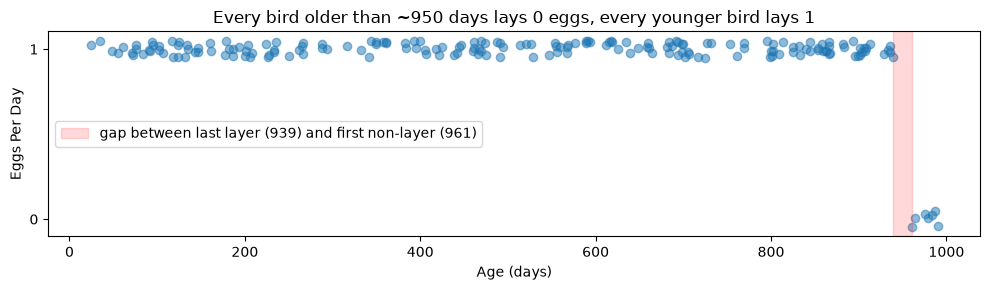

In [5]:
# Each dot is one bird. The small vertical jitter keeps the dots from
# sitting on top of each other.
jitter = np.random.default_rng(0).uniform(-0.05, 0.05, len(birds))
plt.figure(figsize=(10, 3))
plt.scatter(birds['Age'], birds['EggsPerDay'] + jitter, alpha=0.5)
plt.axvspan(939, 961, color='red', alpha=0.15, label='gap between last layer (939) and first non-layer (961)')
plt.yticks([0, 1])
plt.xlabel('Age (days)')
plt.ylabel('Eggs Per Day')
plt.title('Every bird older than ~950 days lays 0 eggs, every younger bird lays 1')
plt.legend(loc='center left')
plt.tight_layout()
plt.show()

Three findings change how the rest of this notebook should be read:

1. **`EggsPerDay` only takes the values 0 and 1.** A regression model's output is therefore the *expected* number of eggs from a bird on a given day, which is the same as the probability that it lays. That is still what the ERP needs: adding the expected values for every bird in a flock gives the expected number of eggs to collect, which Production Tracking can compare against what was actually collected.
2. **Only 7 of the 190 birds lay 0 eggs**, and those are the cases that matter most to a farmer. Every score below rests on those 7 birds.
3. **Age alone separates the two groups perfectly.** Every bird aged 961 days or more lays 0, and every younger bird lays 1. That looks like a rule the dataset's author used to generate the data, not a pattern measured on real hens. Any model that can learn a cut-off on `Age` should score almost perfectly, which says more about how the data was made than about chickens.

This also corrects a guess from Deliverable 1, which expected feed, weight and sunlight to be strong predictors. At the bird level they add nothing (shown in section 3).

The data is biologically odd in other ways as well, which supports the "partly synthetic" warning:

In [6]:
# Real hens start laying at around 18-22 weeks (about 126-154 days old).
young = birds[birds['Age'] < 126]
print(f'{len(young)} birds are younger than 126 days, and {int(young["EggsPerDay"].sum())} of them lay an egg a day')
print('Youngest laying bird:', birds.loc[birds['EggsPerDay'] == 1, 'Age'].min(), 'days old')

22 birds are younger than 126 days, and 22 of them lay an egg a day
Youngest laying bird: 24 days old


### Cleaning: removing impossible records

A bird can't lay before it reaches point of lay, at about 18 weeks (126 days). The birds above are recorded laying an egg a day from as young as 24 days old, so their labels are wrong. Their other values look made up as well: the 24-day-old bird weighs about as much as an adult hen.

These birds are **removed** rather than relabelled as 0, because relabelling would mean inventing data. That leaves the model with no birds younger than 126 days, so it can't learn that laying has a starting age. The `FlockAgent` covers that with a rule taken from poultry science instead of the data: a bird under 126 days old is expected to lay 0 (see section 6). The same cleaning step is in `ml_engine/data.py` as `clean()`.

In [7]:
POINT_OF_LAY_DAYS = 126  # 18 weeks

impossible = (birds['Age'] < POINT_OF_LAY_DAYS) & (birds['EggsPerDay'] > 0)
print('Youngest of the removed birds:')
print(birds.loc[impossible, ['GallusID', 'Age', 'GallusWeight', 'EggsPerDay']].sort_values('Age').head().to_string(index=False))

birds = birds[~impossible].reset_index(drop=True)
print()
print(f'Removed {int(impossible.sum())} birds. {len(birds)} birds left, {int((birds["EggsPerDay"] == 0).sum())} of them lay 0 eggs.')

Youngest of the removed birds:
 GallusID  Age  GallusWeight  EggsPerDay
Marans110   24          1880           1
Marans123   35          2170           1
 Marans61   48          1880           1
Marans105   55          2190           1
Marans138   61          2540           1

Removed 22 birds. 168 birds left, 7 of them lay 0 eggs.


## 2. Encoding the categorical columns

| Column | Kept? | Why |
|---|---|---|
| `Age`, `GallusWeight`, `GallusEggWeight`, `AmountOfFeed`, `SunLightExposure` | yes, numeric | scaled with `StandardScaler` |
| `GallusBreed`, `GallusEggColor`, `GallusCombType`, `GallusLegShanksColor`, `GallusBeakColor`, `GallusPlumage` | yes, categorical | one-hot encoded |
| `GallusID` | no | an identifier, not something that causes laying |
| `Day` | no | only the row's position within each bird's copies |
| `GallusClass` | no | has one value only, and is missing for exactly the Ameraucana birds, so it repeats `GallusBreed` |
| `GallusEarLobesColor` | no | missing for over 90% of birds |

**One-hot encoding** was chosen over ordinal encoding because none of these categories has a natural order (a Splash plumage is not "more" than a Blue one). Ordinal codes would invent an order that a linear model would then treat as real.

Missing values are handled inside the pipeline, not by editing the data. A missing category becomes its own `Unknown` level, and a missing number is filled with the column median. The ERP will not always record leg colour or egg weight for every bird, so the model has to cope without them.

In [8]:
numeric_features = ['Age', 'GallusWeight', 'GallusEggWeight', 'AmountOfFeed', 'SunLightExposure']
categorical_features = ['GallusBreed', 'GallusEggColor', 'GallusCombType',
                        'GallusLegShanksColor', 'GallusBeakColor', 'GallusPlumage']

# Share of missing values in every candidate categorical column, at bird level
print(birds[categorical_features + ['GallusClass', 'GallusEarLobesColor']].isnull().mean().round(3))

GallusBreed             0.000
GallusEggColor          0.000
GallusCombType          0.000
GallusLegShanksColor    0.018
GallusBeakColor         0.018
GallusPlumage           0.000
GallusClass             0.065
GallusEarLobesColor     0.946
dtype: float64


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def build_preprocessor():
    # handle_unknown='ignore' means a breed or colour the model never saw in
    # training is encoded as all zeros, instead of crashing the prediction.
    numeric = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
    categorical = make_pipeline(SimpleImputer(strategy='constant', fill_value='Unknown'),
                                OneHotEncoder(handle_unknown='ignore'))
    return ColumnTransformer([('num', numeric, numeric_features),
                              ('cat', categorical, categorical_features)])


X = birds[numeric_features + categorical_features]
y = birds['EggsPerDay']

# Fitting the preprocessor on its own here is only to show what the encoded
# table looks like. During evaluation it is refitted inside each training
# fold, so the test birds never influence the scaling or the categories.
preview = build_preprocessor()
encoded = preview.fit_transform(X)
encoded = encoded.toarray() if hasattr(encoded, 'toarray') else encoded
encoded = pd.DataFrame(encoded, columns=preview.get_feature_names_out())
print(f'{X.shape[1]} columns in, {encoded.shape[1]} columns out after encoding')
encoded.head()

11 columns in, 29 columns out after encoding


,num__Age,num__GallusWeight,num__GallusEggWeight,num__AmountOfFeed,num__SunLightExposure,cat__GallusBreed_Ameraucana,cat__GallusBreed_Marans,cat__GallusEggColor_Bluish-Green,cat__GallusEggColor_Brown,cat__GallusEggColor_Light Blue,...,cat__GallusPlumage_Black,cat__GallusPlumage_Blue,cat__GallusPlumage_Blue Copper,cat__GallusPlumage_Blue Wheaten,cat__GallusPlumage_Brown Red,cat__GallusPlumage_Buff,cat__GallusPlumage_Silver,cat__GallusPlumage_Splash,cat__GallusPlumage_Splash Copper,cat__GallusPlumage_White
0,1.202408,1.649429,-0.289130,-0.392658,-1.138056,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.415644,-1.099183,1.296625,-0.793265,0.524495,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-1.766736,0.264129,0.865007,1.076233,-1.138056,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-1.395099,1.187662,-1.732818,0.675626,-0.306780,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-1.149976,0.264129,1.448165,1.476839,0.524495,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


## 3. Training and comparing regression models

**Evaluation setup**
- **Repeated stratified 5-fold cross-validation (10 repeats, so 50 train/test splits)**, between birds. With only 168 birds after cleaning, a single train/test split would be too noisy. *Stratified* makes sure every test fold contains some of the 7 non-laying birds, and *repeated* averages out where they happened to land.
- **Metrics:** MAE (average error in eggs per bird per day), RMSE (punishes large misses such as predicting 1 for a bird that lays 0), and R² (how much of the variation is explained compared with always predicting the average).
- **Two baselines**, so that the scores mean something:
  - *Mean baseline*: always predicts the average (about 0.96). Any useful model must beat it.
  - *Age rule*: a hand-written `lay if Age < 950`. This threshold was chosen by looking at all the data, so it is not a fair competitor. It is included to show what the models are really learning.

In [10]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}

candidates = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Linear regression': LinearRegression(),
    'Ridge regression': Ridge(alpha=1.0),
    'Random forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42),
    'Gradient boosting': GradientBoostingRegressor(random_state=42),
}

rows = []
for name, regressor in candidates.items():
    pipeline = Pipeline([('prep', build_preprocessor()), ('model', regressor)])
    scores = cross_validate(pipeline, X, y, cv=cv, scoring=scoring)
    rows.append({
        'Model': name,
        'MAE': -scores['test_MAE'].mean(),
        'RMSE': -scores['test_RMSE'].mean(),
        'R2': scores['test_R2'].mean(),
        'R2 std': scores['test_R2'].std(),
    })

# The age rule has nothing to train, so it is just applied to every bird
rule = (birds['Age'] < 950).astype(int)
rows.append({'Model': 'Age rule (Age < 950, not trained)',
             'MAE': mean_absolute_error(y, rule),
             'RMSE': np.sqrt(mean_squared_error(y, rule)),
             'R2': r2_score(y, rule), 'R2 std': np.nan})

results = pd.DataFrame(rows).set_index('Model').round(4)
results

,MAE,RMSE,R2,R2 std
Model,,,,
Mean baseline,0.0798,0.1972,-0.0077,0.0007
Linear regression,0.1092,0.1938,0.0145,0.1079
Ridge regression,0.1060,0.1925,0.0289,0.1009
Random forest,0.0021,0.0081,0.9976,0.0037
Gradient boosting,0.0000,0.0000,1.0000,0.0000
"Age rule (Age < 950, not trained)",0.0000,0.0000,1.0000,NaN


**Reading the table**
- **Linear and ridge regression are no better than the mean baseline.** Their R² is close to 0, and their MAE is actually worse. The relationship is a step at about 950 days, not a straight line. A line fitted through 161 ones and 7 zeros at the old end only tilts slightly, so it is a little wrong for every bird and right for none of the non-layers.
- **The tree models score almost perfectly.** Trees split on thresholds, and a single split on `Age` is all this data needs.
- **The age rule matches them.** That is the key point: the models have rediscovered the rule behind the data. The near-perfect score is evidence that the pipeline works end to end, not that egg production is this predictable on a real farm.

Two checks confirm that `Age` is doing all the work:

In [11]:
# Check 1: a random forest given only Age scores the same as one given every feature.
age_only = Pipeline([('prep', ColumnTransformer([('age', 'passthrough', ['Age'])])),
                     ('model', RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42))])
scores = cross_validate(age_only, X, y, cv=cv, scoring=scoring)
print(f"Age-only random forest:  MAE {-scores['test_MAE'].mean():.4f}   R2 {scores['test_R2'].mean():.3f}")
print(f"All-features random forest: MAE {results.loc['Random forest', 'MAE']:.4f}   R2 {results.loc['Random forest', 'R2']:.3f}")

Age-only random forest:  MAE 0.0020   R2 0.998
All-features random forest: MAE 0.0021   R2 0.998


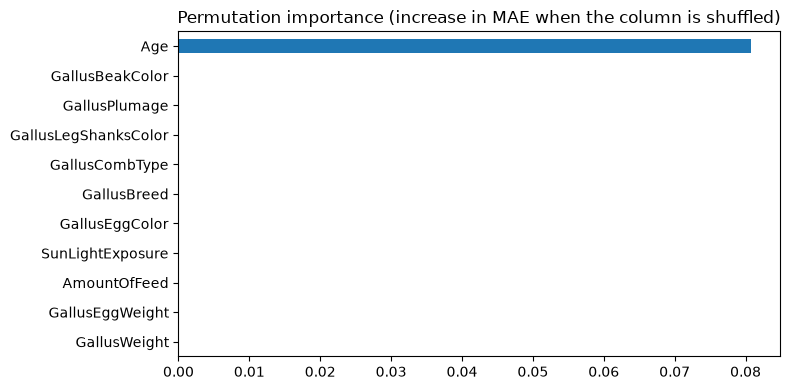

In [12]:
from sklearn.inspection import permutation_importance

# Check 2: permutation importance shuffles one original column at a time and
# measures how much worse the fitted model gets. It is computed on the training
# data, so it shows what the model relies on rather than how well it generalises.
forest = Pipeline([('prep', build_preprocessor()),
                   ('model', RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42))])
forest.fit(X, y)
importance = permutation_importance(forest, X, y, n_repeats=20, random_state=42, scoring='neg_mean_absolute_error')
importance = pd.Series(importance.importances_mean, index=X.columns).sort_values()

importance.plot.barh(figsize=(8, 4), title='Permutation importance (increase in MAE when the column is shuffled)')
plt.tight_layout()
plt.show()

## 4. Choosing the final model

On these scores gradient boosting (R² 1.000) edges out the random forest (R² ≈ 0.998). **The random forest is still the better choice for the ERP**, because of how each model behaves near the cut-off:

- Gradient boosting learns a hard step, so a bird's expected eggs jump straight from 1 to 0.
- The random forest averages 300 trees, each trained on a different bootstrap sample of birds. The trees disagree slightly about where the cut-off is, so near it the forest gives values in between.

There is no data at all between 939 and 961 days, so the model genuinely cannot know where the drop happens. An "expected eggs" figure of, say, 0.6 is more honest there than a confident 1 or 0. It is also what lets the agent warn that a bird is *approaching* the end of lay.

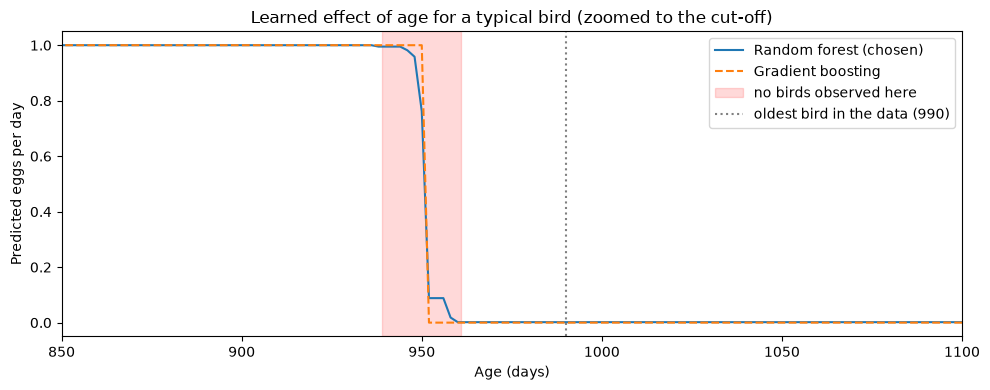

In [13]:
gboost = Pipeline([('prep', build_preprocessor()), ('model', GradientBoostingRegressor(random_state=42))]).fit(X, y)

# A "typical" bird: median of each number and most common value of each
# category. Only Age is varied, so the curve shows what each model has learned
# about age on its own.
typical = {c: X[c].median() for c in numeric_features}
typical.update({c: X[c].mode()[0] for c in categorical_features})
ages = np.arange(0, 1101, 2)
grid = pd.DataFrame([typical] * len(ages))
grid['Age'] = ages

plt.figure(figsize=(10, 4))
plt.plot(ages, forest.predict(grid), label='Random forest (chosen)')
plt.plot(ages, gboost.predict(grid), '--', label='Gradient boosting')
plt.axvspan(939, 961, color='red', alpha=0.15, label='no birds observed here')
plt.axvline(birds['Age'].max(), color='grey', linestyle=':', label='oldest bird in the data (990)')
plt.xlim(850, 1100)
plt.xlabel('Age (days)')
plt.ylabel('Predicted eggs per day')
plt.title('Learned effect of age for a typical bird (zoomed to the cut-off)')
plt.legend()
plt.tight_layout()
plt.show()

Past the oldest bird in the data (990 days), both models just carry their last value forward. Tree models cannot extrapolate, so predictions for birds older than anything they were trained on are guesses.

The same happens at the young end. After cleaning there are no birds under 126 days, so the models carry "lays 1 egg" all the way back to age 0. That is why the agent applies a point-of-lay rule for young birds instead of trusting the model there.

**Saving the model.** The cross-validation scores above estimate how well the model works. The model that gets saved is refitted on all 168 cleaned birds, because there are too few to hold any back. It is stored in the same format that `ml_engine/model.py` uses, so the `FlockAgent` and the API can load it directly.

In [14]:
import joblib
import sklearn

os.makedirs('models', exist_ok=True)
joblib.dump({
    'pipeline': forest,  # already fitted on all birds above
    'metrics': {'mae': results.loc['Random forest', 'MAE'],
                'rmse': results.loc['Random forest', 'RMSE'],
                'r2': results.loc['Random forest', 'R2']},
    'n_birds': len(birds),
    'n_removed': int(impossible.sum()),  # birds dropped by the cleaning step
    # a pickled model is only safe to load with the scikit-learn version that saved it
    'sklearn_version': sklearn.__version__,
}, 'models/egg_model.joblib')
print('Saved models/egg_model.joblib')

# Quick check that the saved model gives sensible answers
check = pd.DataFrame([typical] * 3)
check['Age'] = [400, 950, 990]
print(pd.Series(forest.predict(check).round(3), index=['400 days', '950 days', '990 days'], name='expected eggs'))

Saved models/egg_model.joblib
400 days    1.000
950 days    0.762
990 days    0.002
Name: expected eggs, dtype: float64


## 5. Limitations — what these results do and don't show

- **The near-perfect accuracy comes from the dataset's construction.** The model has learned "hens older than about 950 days stop laying". That shows the pipeline (encoding, training, evaluation, saving, serving) works end to end. It is not evidence about real hens.
- **The sample is tiny where it matters.** 168 birds after cleaning, and only 7 that don't lay. On real data, a score based on 7 examples would have very wide error bars.
- **The biology is unrealistic.** Before cleaning, birds laid from 24 days old. Cleaning removed those 22 birds, but only because they broke an obvious rule, and subtler errors can't be caught that way. The lay rate also stays flat until it stops suddenly, whereas real flocks peak at around 25–30 weeks and then decline gradually.
- **Feed, light and weight show no effect, but only in this dataset.** In reality they clearly matter. The data simply wasn't generated with any link between them and laying.
- **The target is a 0/1 value per bird per day.** Real ERP records are usually daily egg counts per flock or house (hen-day production %). That would make this a genuine regression problem and a far more useful one.

**What real data would need:** daily egg counts per flock, feed issued, flock age, mortality, lighting programme and house temperature from the farms in the study. With repeated records over time, the split should then be **grouped by flock and ordered in time** (train on earlier weeks, test on later ones), so the model is tested the way it will be used: forecasting the future for flocks it already knows.

The code is written for that switch. The pipeline imputes missing columns, ignores unseen categories, and `ml_engine/data.py` refuses to collapse rows once a bird's records start changing from day to day.

## 6. How the ERP uses the model — the `FlockAgent`

The model on its own only produces numbers. The ERP needs decisions, so `ml_engine/agent.py` wraps the model in a **model-based reflex agent** (Russell & Norvig): it keeps a model of how the world works (the regressor) and applies condition-action rules to what it perceives.

**PEAS description**

| | |
|---|---|
| **Performance measure** | eggs collected vs. expected; feed spent on birds that are not laying; how early drops in laying are caught |
| **Environment** | a poultry flock, as recorded day by day in the ERP |
| **Actuators** | recommendations sent to the ERP's Production Tracking and Feed Management modules (check bird, plan replacement, cull or change feed, investigate a flock-wide shortfall) |
| **Sensors** | the day's records for each bird: attributes, feed given and eggs collected |

**Rules**

| Condition | Flag | Recommended action |
|---|---|---|
| age under 126 days (point of lay) | `too_young_to_lay` | expected eggs set to 0, whatever the model says; keep the bird on grower feed |
| too young now, but laying age within 30 days | `start_of_lay_soon` | move it to layer feed and get nest boxes ready |
| expected eggs < 0.5 (birds old enough to lay) | `not_expected_to_lay` | cull the bird or move it off layer feed (the agent reports how much feed these birds eat) |
| laying now, but expected < 0.5 once aged 30 days forward | `end_of_lay_soon` | plan replacement birds |
| 0 eggs collected, but expected ≥ 0.8 | `missed_lay` | check the bird for illness, stress or broodiness |
| shortfall *not* explained by `missed_lay` birds ≥ 10% of expected (and at least 1 egg) | flock level | check feed, water, lighting and egg collection across the house |

**Running it** (from the repo root, after `pip install -r requirements.txt`):
```
python -m ml_engine.train                              # trains and saves models/egg_model.joblib
python -m ml_engine.agent examples/flock_today.json    # reviews a sample day
uvicorn ml_engine.api:app --reload                     # HTTP service for the ERP, docs at /docs
```